In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
import numpy as np
import os
from glob import glob
from torch_geometric.utils.smiles import x_map

from mol_faith.data.data_managers.smiles_data_manager import SMILESTokenizer
from mol_faith.data.data_managers.tokenization_helper import test_round_trip_fidelity
from mol_faith.data.create_dataset.create_gt_data import generate_gt_data
from mol_faith.target_extraction.benzene_substructure_extraction import BenzeneSubstructureExtractor
from mol_faith.target_extraction.largest_conjugated_system_extraction import LargestConjugatedSystemExtractor
from mol_faith.target_extraction.hbond_donor_extraction import HBondDonorExtractor

In [2]:
tokenizer = SMILESTokenizer()

# Create Raw Dataset

In [ ]:
xls = pd.ExcelFile('../../../data/raw/Dataset_and_Predictions.xlsx')
train_val_data = pd.read_excel(xls, 'model')
test_data = pd.read_excel(xls, 'test')

In [8]:
print(train_val_data.columns)
print(test_data.columns)

Index(['SMILES', 'CAS', 'ChemID', 'logP\nexperimental\n(corrected)',
       'assignment\nDNNtaut', 'logP\npredicted\nDNNtaut',
       'assignment\nDNNmono', 'logP\npredicted\nDNNmono',
       'canonical \nSMILES'],
      dtype='object')
Index(['SMILES', 'CAS', 'ChemID', 'logP\nexperimental\n(corrected)',
       'logP\npredicted', 'DNNtaut', 'DNNmono', 'KOWWIN', 'OCHEM', 'ALOGPS',
       'JChem', 'DataWarrior', 'ACD GALAS',
       'COSMO-RS (tautomers not considered)', 'assignments', 'original SMILES',
       'original SMILES\nwithout ions\n',
       'original SMILES randomly selected (including tautomers)',
       'original SMILES most likely tautomer', 'SMILES randomly selected',
       'SMILES randomly selected without ions', 'canonical SMILES',
       'SMILES including explicit H atoms', 'classified as ion?'],
      dtype='object')


In [9]:
train_data = train_val_data[train_val_data['assignment\nDNNmono'] == 'training'][['SMILES', 'logP\nexperimental\n(corrected)']]
val_data = train_val_data[train_val_data['assignment\nDNNmono'] == 'validation'][['SMILES', 'logP\nexperimental\n(corrected)']]
test_data = test_data[test_data['original SMILES'] == 'test'][['SMILES', 'logP\nexperimental\n(corrected)']]

In [10]:
# Make sure that I have all the data
print(f'Length of train {len(train_data)}')
print(f'Length of val {len(val_data)}')
print(f'Length of test {len(test_data)}')

Length of train 10000
Length of val 2500
Length of test 1389


In [11]:
raw_data = pd.concat([train_data, val_data, test_data])
raw_data.rename(columns={'logP\nexperimental\n(corrected)':'Target'}, inplace=True)
raw_data.reset_index(drop=True, inplace=True)

In [ ]:
# raw_data.to_csv('../../../data/raw/raw_data.csv', index=False)

# Clean Data

In [ ]:
clean_data = pd.read_csv('../../../data/cleaned/cleaned_data.csv')
clean_data

,SMILES,Target
0,C=O,0.350
1,C[C@@H]1C[C@H]2[C@@H]3CC=C4CC(=O)C=C[C@]4(C)[C...,1.885
2,CC(=O)OCC(=O)[C@@]1(O)CCC2C3CC=C4CC(=O)CC[C@]4...,2.190
3,CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CC=C4CC(=...,2.100
4,CCC1(c2ccccc2)C(=O)NC(=O)NC1=O,1.470
...,...,...
13884,N#CCCOC1Cc2c(O)cc(O)cc2OC1c1ccc(O)c(O)c1,0.960
13885,O=c1cc(CSc2ccccn2)occ1O,1.140
13886,Oc1cccc2c(C=Nc3ccccc3)c3cccc(O)c3c(O)c12,4.960
13887,O=C1Nc2cc(Cl)ccc2C(=O)[C]1c1cccc(-n2ccc3ccccc3...,5.530


In [36]:
from mol_faith.data.data_managers.tokenization_helper import extract_elements_from_smiles


result = extract_elements_from_smiles(clean_data['SMILES'].tolist())
result

{'elements': ['As',
  'B',
  'Br',
  'C',
  'Cl',
  'F',
  'I',
  'N',
  'O',
  'P',
  'S',
  'Se',
  'Si'],
 'failed_smiles': []}

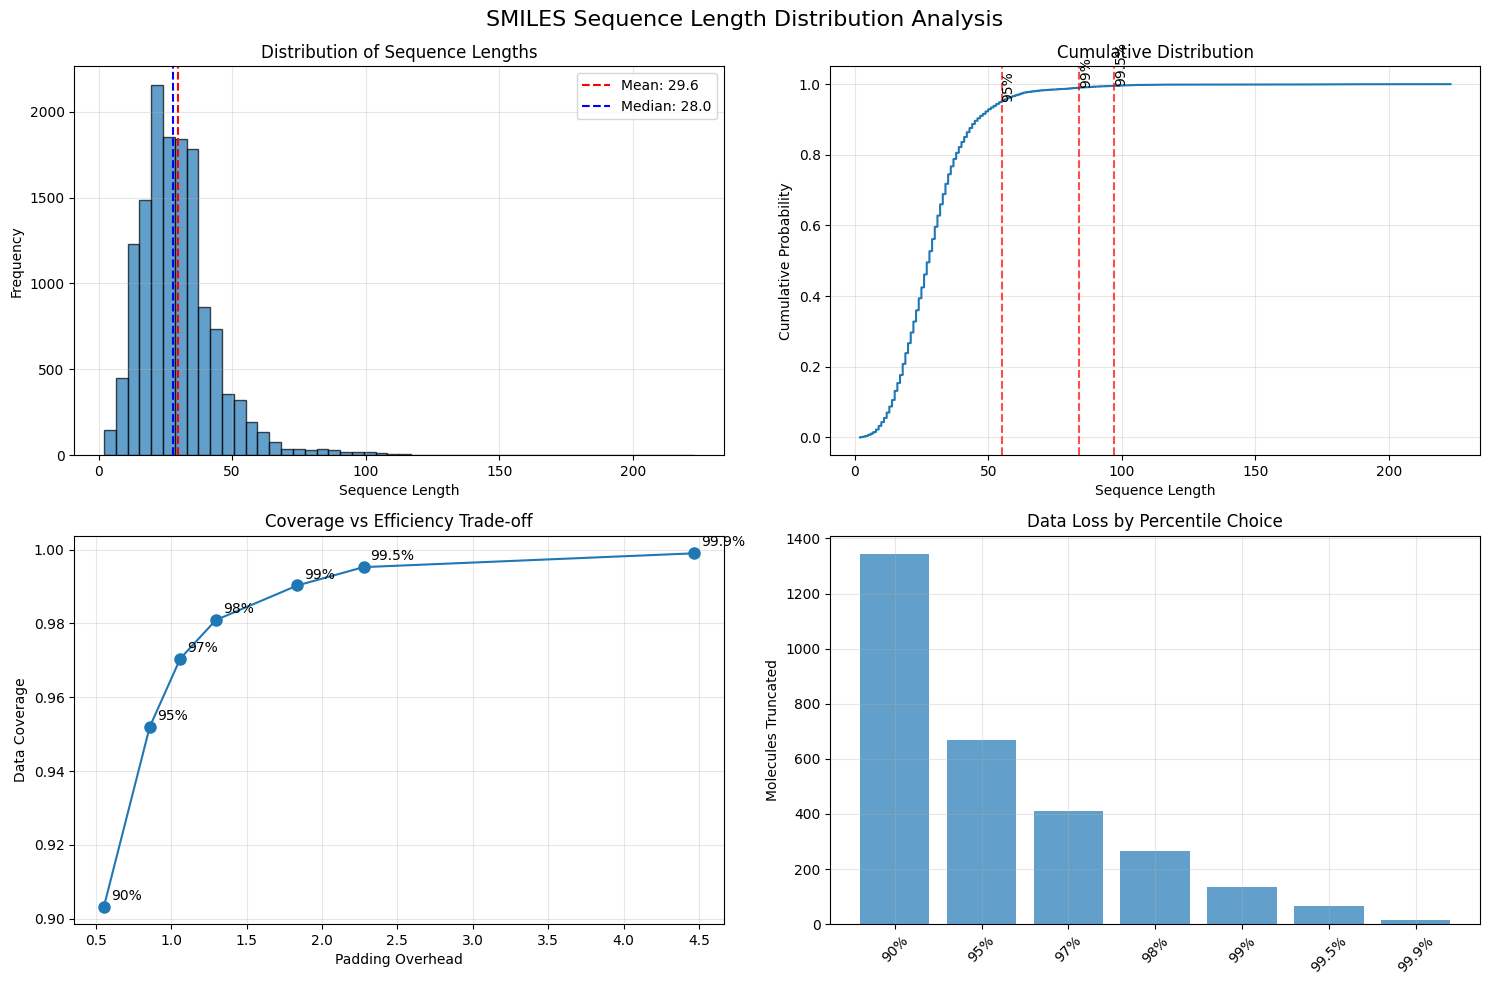


SEQUENCE LENGTH ANALYSIS SUMMARY
Dataset: 13889 molecules
Valid tokenization: 13889 (100.0%)
Mean length: 29.6 ± 15.1 tokens
Range: 2 - 223 tokens

PERCENTILE VALUES:
----------------------------------------
   50th percentile:  28 tokens | Coverage:  52.7% | Truncated: 6570 | Padding:  -5.5%
   75th percentile:  36 tokens | Coverage:  76.7% | Truncated: 3234 | Padding:  21.6%
   90th percentile:  46 tokens | Coverage:  90.3% | Truncated: 1343 | Padding:  55.3%
   95th percentile:  55 tokens | Coverage:  95.2% | Truncated:  667 | Padding:  85.7%
   97th percentile:  61 tokens | Coverage:  97.0% | Truncated:  410 | Padding: 106.0%
   98th percentile:  68 tokens | Coverage:  98.1% | Truncated:  265 | Padding: 129.6%
   99th percentile:  84 tokens | Coverage:  99.0% | Truncated:  135 | Padding: 183.6%
 99.5th percentile:  97 tokens | Coverage:  99.5% | Truncated:   66 | Padding: 227.5%
 99.9th percentile: 162 tokens | Coverage:  99.9% | Truncated:   14 | Padding: 447.0%


{'total_molecules': 13889,
 'valid_molecules': 13889,
 'failed_tokenization': 0,
 'mean': 29.615883072935418,
 'median': 28.0,
 'std': 15.1022047527263,
 'min': 2,
 'max': 223,
 'percentiles': {50: 28,
  75: 36,
  90: 46,
  95: 55,
  97: 61,
  98: 68,
  99: 84,
  99.5: 97,
  99.9: 162},
 'coverage_analysis': {'50th_percentile': {'max_length': 28,
   'coverage': 0.5269637842897257,
   'molecules_truncated': 6570,
   'avg_tokens_lost': 12.691019786910198},
  '75th_percentile': {'max_length': 36,
   'coverage': 0.7671538627690978,
   'molecules_truncated': 3234,
   'avg_tokens_lost': 13.42517006802721},
  '90th_percentile': {'max_length': 46,
   'coverage': 0.9033047735618115,
   'molecules_truncated': 1343,
   'avg_tokens_lost': 15.695457930007446},
  '95th_percentile': {'max_length': 55,
   'coverage': 0.9519763841889265,
   'molecules_truncated': 667,
   'avg_tokens_lost': 17.97001499250375},
  '97th_percentile': {'max_length': 61,
   'coverage': 0.9704802361581107,
   'molecules_trunc

In [4]:
from mol_faith.data.preprocessing.filter_helper import analyze_sequence_length_distribution


analyze_sequence_length_distribution(tokenizer, clean_data['SMILES'].tolist(), plot=True)

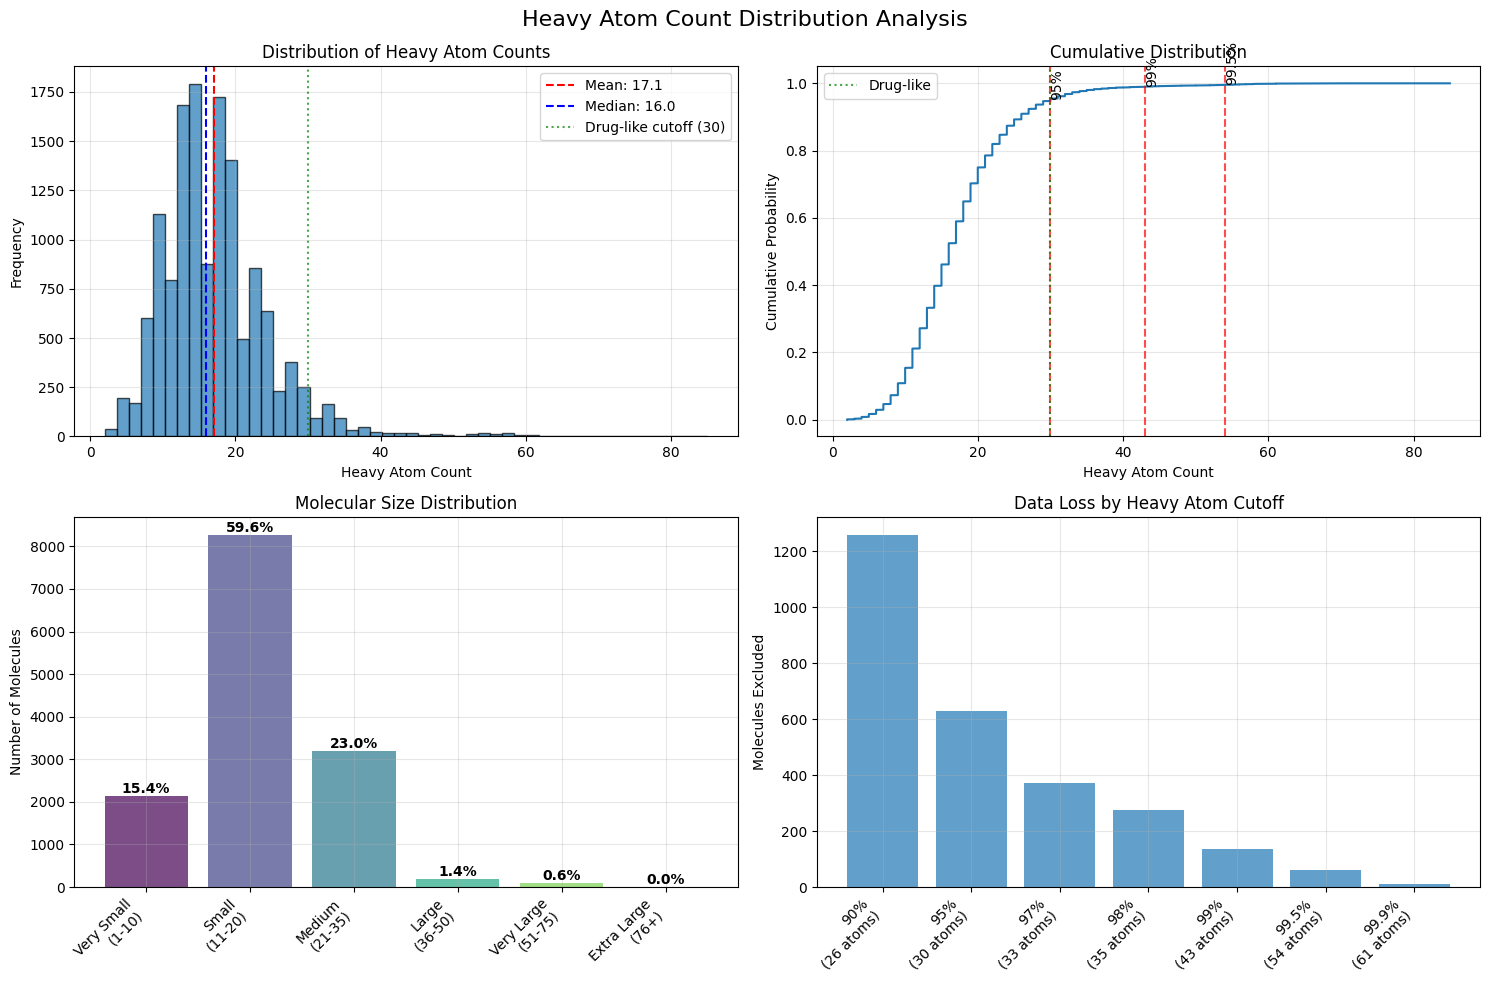


HEAVY ATOM COUNT ANALYSIS SUMMARY
Dataset: 13889 molecules
Valid parsing: 13889 (100.0%)
Mean heavy atoms: 17.1 ± 7.4
Range: 2 - 85 heavy atoms

SIZE CATEGORY DISTRIBUTION:
----------------------------------------
  Very Small ( 1-10):  2138 molecules ( 15.4%)
       Small (11-20):  8276 molecules ( 59.6%)
      Medium (21-35):  3199 molecules ( 23.0%)
       Large (36-50):   188 molecules (  1.4%)
  Very Large (51-75):    87 molecules (  0.6%)
 Extra Large (  76+):     1 molecules (  0.0%)

PERCENTILE CUTOFFS:
----------------------------------------
   50th percentile: 16 atoms | Coverage:  52.4% | Excluded: 6605 molecules
   75th percentile: 21 atoms | Coverage:  78.5% | Excluded: 2980 molecules
   90th percentile: 26 atoms | Coverage:  90.9% | Excluded: 1259 molecules
   95th percentile: 30 atoms | Coverage:  95.5% | Excluded:  630 molecules
   97th percentile: 33 atoms | Coverage:  97.3% | Excluded:  370 molecules
   98th percentile: 35 atoms | Coverage:  98.0% | Excluded:  276 m

{'total_molecules': 13889,
 'valid_molecules': 13889,
 'failed_parsing': 0,
 'mean': 17.119807041543666,
 'median': 16.0,
 'std': 7.432847380392341,
 'min': 2,
 'max': 85,
 'percentiles': {50: 16,
  75: 21,
  90: 26,
  95: 30,
  97: 33,
  98: 35,
  99: 43,
  99.5: 54,
  99.9: 61},
 'coverage_analysis': {'50th_percentile': {'cutoff': 16,
   'coverage': 0.5244438044495644,
   'molecules_excluded': 6605,
   'avg_excess_atoms': 6.797577592732778},
  '75th_percentile': {'cutoff': 21,
   'coverage': 0.7854417164662683,
   'molecules_excluded': 2980,
   'avg_excess_atoms': 6.746979865771812},
  '90th_percentile': {'cutoff': 26,
   'coverage': 0.9093527251781985,
   'molecules_excluded': 1259,
   'avg_excess_atoms': 7.347100873709293},
  '95th_percentile': {'cutoff': 30,
   'coverage': 0.954640362877097,
   'molecules_excluded': 630,
   'avg_excess_atoms': 8.43968253968254},
  '97th_percentile': {'cutoff': 33,
   'coverage': 0.973360213118295,
   'molecules_excluded': 370,
   'avg_excess_atoms

In [5]:
from mol_faith.data.preprocessing.filter_helper import analyze_heavy_atom_distribution


analyze_heavy_atom_distribution(clean_data['SMILES'].tolist(), plot=True)

# Clean and Filtered

In [ ]:
clean_and_filtered_data = pd.read_csv('../../../data/cleaned_and_filtered/filtered_data.csv')
clean_and_filtered_data

,SMILES,Target
0,C=O,0.350
1,C[C@@H]1C[C@H]2[C@@H]3CC=C4CC(=O)C=C[C@]4(C)[C...,1.885
2,CC(=O)OCC(=O)[C@@]1(O)CCC2C3CC=C4CC(=O)CC[C@]4...,2.190
3,CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CC=C4CC(=...,2.100
4,CCC1(c2ccccc2)C(=O)NC(=O)NC1=O,1.470
...,...,...
13787,N#CCCOC1Cc2c(O)cc(O)cc2OC1c1ccc(O)c(O)c1,0.960
13788,O=c1cc(CSc2ccccn2)occ1O,1.140
13789,Oc1cccc2c(C=Nc3ccccc3)c3cccc(O)c3c(O)c12,4.960
13790,O=C1Nc2cc(Cl)ccc2C(=O)[C]1c1cccc(-n2ccc3ccccc3...,5.530


## Build Vocabulary

In [5]:
tokenizer.build_vocab_from_corpus(clean_and_filtered_data['SMILES'].tolist())
tokenizer.vocab_size

41

In [6]:
tokenizer.id_to_token

{0: '[PAD]',
 1: '[UNK]',
 2: '[MASK]',
 3: '#',
 4: '(',
 5: ')',
 6: '+',
 7: '-',
 8: '/',
 9: '1',
 10: '2',
 11: '3',
 12: '4',
 13: '5',
 14: '6',
 15: '7',
 16: '=',
 17: '@',
 18: '@@',
 19: 'As',
 20: 'B',
 21: 'Br',
 22: 'C',
 23: 'Cl',
 24: 'F',
 25: 'H',
 26: 'I',
 27: 'N',
 28: 'O',
 29: 'P',
 30: 'S',
 31: 'Se',
 32: 'Si',
 33: '[',
 34: '\\',
 35: ']',
 36: 'c',
 37: 'n',
 38: 'o',
 39: 's',
 40: 'se'}

In [ ]:
test_round_trip_fidelity(tokenizer, clean_and_filtered_data['SMILES'].tolist(), max_length=100)

Testing all 13792 SMILES
Testing encode-decode round-trip fidelity...

ROUND-TRIP FIDELITY TEST RESULTS
Total SMILES tested: 13792
Perfect matches: 13792 (100.00%)
🎉 PERFECT FIDELITY! All SMILES round-tripped correctly.


{'total_tested': 13792,
 'perfect_matches': 13792,
 'failed_roundtrips': [],
 'truncation_losses': [],
 'tokenization_failures': [],
 'unknown_token_issues': [],
 'success_rate': 1.0,
 'perfect_success_rate': 1.0,
 'failure_breakdown': {'truncation_losses': 0,
  'unknown_token_issues': 0,
  'other_failures': 0,
  'tokenization_failures': 0}}

In [ ]:
tokenizer.save_vocab('../../../data/cleaned_and_filtered/tokenizer_vocab.txt')

## Analysis of features

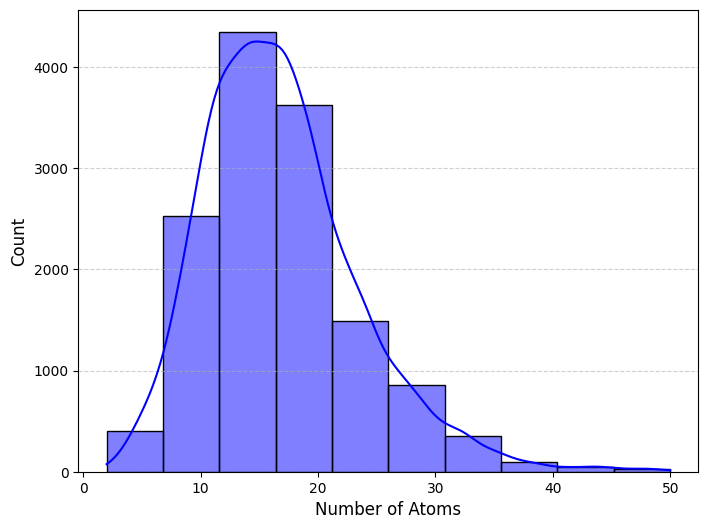

In [9]:
def count_atoms(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return mol.GetNumAtoms() if mol else None

clean_and_filtered_data['num_atoms'] = clean_and_filtered_data['SMILES'].apply(count_atoms)

plt.figure(figsize=(8, 6))
sns.histplot(clean_and_filtered_data['num_atoms'].dropna(), bins=10, kde=True, color="blue")

plt.xlabel("Number of Atoms", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

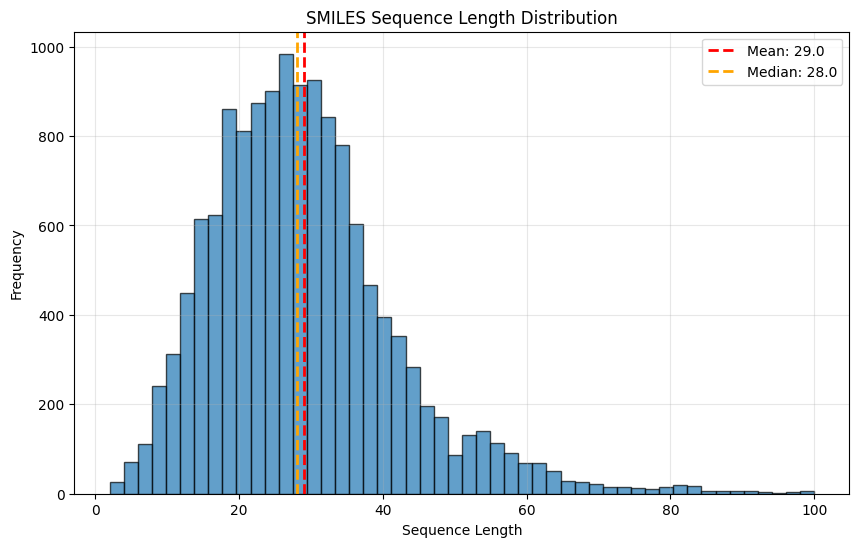

Mean length: 29.03
Min length: 2
Max length: 100


In [13]:
def plot_smiles_length_distribution(smiles_data, tokenizer):
    """
    Simple plot of SMILES sequence length distribution
    
    Parameters:
    -----------
    smiles_data : list or pd.Series
        List/Series of SMILES strings
    tokenizer : object
        Tokenizer object with tokenize() method
    """
    
    # Calculate sequence lengths
    sequence_lengths = []
    
    for smiles in smiles_data:
        try:
            tokens = tokenizer.tokenize(smiles)
            sequence_lengths.append(len(tokens))
        except:
            continue  # Skip failed tokenizations
    
    lengths = np.array(sequence_lengths)
    
    # Create the plot
    plt.figure(figsize=(10, 6))
    plt.hist(lengths, bins=50, alpha=0.7, edgecolor='black')
    plt.axvline(lengths.mean(), color='red', linestyle='--', linewidth=2, 
                label=f'Mean: {lengths.mean():.1f}')
    plt.axvline(np.median(lengths), color='orange', linestyle='--', linewidth=2, 
                label=f'Median: {np.median(lengths):.1f}')
    
    plt.xlabel('Sequence Length')
    plt.ylabel('Frequency')
    plt.title('SMILES Sequence Length Distribution')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Print basic stats
    print(f"Mean length: {lengths.mean():.2f}")
    print(f"Min length: {lengths.min()}")
    print(f"Max length: {lengths.max()}")

plot_smiles_length_distribution(clean_and_filtered_data['SMILES'], tokenizer)

In [ ]:
def extract_node_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None  # Handle invalid SMILES

    features = {
        'atomic_num': [],
        'chirality': [],
        'degree': [],
        'formal_charge': [],
        'num_hs': [],
        'num_radical_electrons': [],
        'hybridization': [],
        'is_aromatic': [],
        'is_in_ring': []
    }

    for atom in mol.GetAtoms():
        features['atomic_num'].append(x_map['atomic_num'].index(atom.GetAtomicNum()))
        features['chirality'].append(x_map['chirality'].index(str(atom.GetChiralTag())))
        features['degree'].append(x_map['degree'].index(atom.GetTotalDegree()))
        features['formal_charge'].append(x_map['formal_charge'].index(atom.GetFormalCharge()))
        features['num_hs'].append(x_map['num_hs'].index(atom.GetTotalNumHs()))
        features['num_radical_electrons'].append(x_map['num_radical_electrons'].index(
            atom.GetNumRadicalElectrons()))
        features['hybridization'].append(x_map['hybridization'].index(str(atom.GetHybridization())))
        features['is_aromatic'].append(x_map['is_aromatic'].index(atom.GetIsAromatic()))
        features['is_in_ring'].append(x_map['is_in_ring'].index(atom.IsInRing()))

    return features

def process_dataframe(df):
    all_features = {key: [] for key in [
        'atomic_num', 'chirality', 'degree', 'formal_charge',
        'num_hs', 'num_radical_electrons', 'hybridization',
        'is_aromatic', 'is_in_ring'
    ]}

    for smiles in df['SMILES']:
        node_features = extract_node_features(smiles)
        if node_features:
            for key in all_features:
                all_features[key].extend(node_features[key])

    return pd.DataFrame(all_features)


def plot_categorical_features(df_features, figsize=(20, 15)):
    """
    Plot distributions for all categorical features in the dataframe
    """
    # Get number of features
    n_features = len(df_features.columns)
    
    # Calculate grid dimensions
    n_cols = 4
    n_rows = (n_features + n_cols - 1) // n_cols
    
    # Create subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    fig.suptitle('Categorical Feature Distributions', fontsize=20, fontweight='bold')
    
    # Flatten axes array for easier indexing
    axes_flat = axes.flatten() if n_features > 1 else [axes]
    
    for i, column in enumerate(df_features.columns):
        ax = axes_flat[i]
        
        # Get value counts and sort by index (value)
        value_counts = df_features[column].value_counts().sort_index()
        
        # Create bar plot
        bars = ax.bar(range(len(value_counts)), value_counts.values, 
                     alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Set x-axis labels
        ax.set_xticks(range(len(value_counts)))
        ax.set_xticklabels(value_counts.index, rotation=45, ha='right')
        
        # Add value labels on bars
        for bar, count in zip(bars, value_counts.values):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
                   f'{count}', ha='center', va='bottom', fontsize=8)
        
        # Set title and labels
        ax.set_title(f'{column}\n({len(value_counts)} unique values)', fontweight='bold', fontsize=10)
        ax.set_xlabel('Category')
        ax.set_ylabel('Count')
        ax.grid(True, alpha=0.3, axis='y')
    
    # Hide empty subplots
    for i in range(n_features, len(axes_flat)):
        axes_flat[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()

def plot_feature_frequency_table(df_features):
    """
    Create a frequency table heatmap showing category distributions
    """
    # Calculate frequency for each feature
    freq_data = []
    feature_names = []
    
    for col in df_features.columns:
        value_counts = df_features[col].value_counts().sort_index()
        freq_data.append(value_counts.values)
        feature_names.append(col)
    
    # Create DataFrame for easier plotting
    max_len = max(len(row) for row in freq_data)
    freq_matrix = np.zeros((len(feature_names), max_len))
    
    for i, row in enumerate(freq_data):
        freq_matrix[i, :len(row)] = row
    
    # Plot heatmap
    plt.figure(figsize=(max_len, len(feature_names) * 0.5 + 2))
    sns.heatmap(freq_matrix, 
                yticklabels=feature_names,
                cmap='Blues', 
                annot=True, 
                fmt='.0f',
                cbar_kws={'label': 'Frequency'})
    
    plt.title('Feature Category Frequencies', fontsize=16, fontweight='bold')
    plt.xlabel('Category Index')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

def analyze_categorical_features(df_features):
    """
    Comprehensive categorical feature analysis
    """
    print("=== CATEGORICAL FEATURE ANALYSIS ===\n")
    
    print(f"Dataset Shape: {df_features.shape}")
    print(f"Number of Features: {df_features.shape[1]}")
    print(f"Number of Samples: {df_features.shape[0]}\n")
    
    print("Feature Information:")
    print("-" * 80)
    print(f"{'Feature':<25} | {'Unique':<8} | {'Most Common':<15} | {'Frequency':<10} | {'Missing':<8}")
    print("-" * 80)
    
    for col in df_features.columns:
        unique_vals = df_features[col].nunique()
        missing_vals = df_features[col].isnull().sum()
        
        # Get most common value and its frequency
        value_counts = df_features[col].value_counts()
        most_common = value_counts.index[0] if len(value_counts) > 0 else 'N/A'
        most_common_freq = value_counts.iloc[0] if len(value_counts) > 0 else 0
        
        print(f"{col:<25} | {unique_vals:<8} | {str(most_common):<15} | {most_common_freq:<10} | {missing_vals:<8}")
    
    print("\n" + "="*80 + "\n")

def create_category_summary_table(df_features):
    """
    Create a summary table of all categories
    """
    summary_data = []
    
    for col in df_features.columns:
        value_counts = df_features[col].value_counts()
        for category, count in value_counts.items():
            percentage = (count / len(df_features)) * 100
            summary_data.append({
                'Feature': col,
                'Category': category,
                'Count': count,
                'Percentage': f"{percentage:.2f}%"
            })
    
    summary_df = pd.DataFrame(summary_data)
    return summary_df

# Main execution functions
def full_categorical_analysis(df_features):
    """
    Run complete categorical feature analysis
    """
    # 1. Basic analysis
    analyze_categorical_features(df_features)
    
    # 2. Plot all feature distributions
    plot_categorical_features(df_features)
    
    # 4. Create and display summary table
    summary_table = create_category_summary_table(df_features)
    print("Category Summary Table (first 20 rows):")
    print(summary_table.head(20))
    
    return summary_table

# Quick plotting function
def quick_categorical_plot(df_features, max_features=6):
    """
    Quick plot of first few features
    """
    features_to_plot = df_features.columns[:max_features]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    
    for i, col in enumerate(features_to_plot):
        value_counts = df_features[col].value_counts().sort_index()
        
        bars = axes[i].bar(range(len(value_counts)), value_counts.values, alpha=0.7)
        axes[i].set_title(col, fontweight='bold')
        axes[i].set_xticks(range(len(value_counts)))
        axes[i].set_xticklabels(value_counts.index, rotation=45)
        
        # Add count labels
        for bar, count in zip(bars, value_counts.values):
            height = bar.get_height()
            axes[i].text(bar.get_x() + bar.get_width()/2., height,
                        f'{count}', ha='center', va='bottom', fontsize=8)
    
    # Hide unused subplots
    for i in range(len(features_to_plot), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()

=== CATEGORICAL FEATURE ANALYSIS ===

Dataset Shape: (232367, 9)
Number of Features: 9
Number of Samples: 232367

Feature Information:
--------------------------------------------------------------------------------
Feature                   | Unique   | Most Common     | Frequency  | Missing 
--------------------------------------------------------------------------------
atomic_num                | 13       | 6               | 164156     | 0       
chirality                 | 3        | 0               | 231239     | 0       
degree                    | 5        | 3               | 121353     | 0       
formal_charge             | 3        | 5               | 228767     | 0       
num_hs                    | 4        | 0               | 106255     | 0       
num_radical_electrons     | 2        | 0               | 232017     | 0       
hybridization             | 4        | 3               | 154393     | 0       
is_aromatic               | 2        | 0               | 133961     | 0

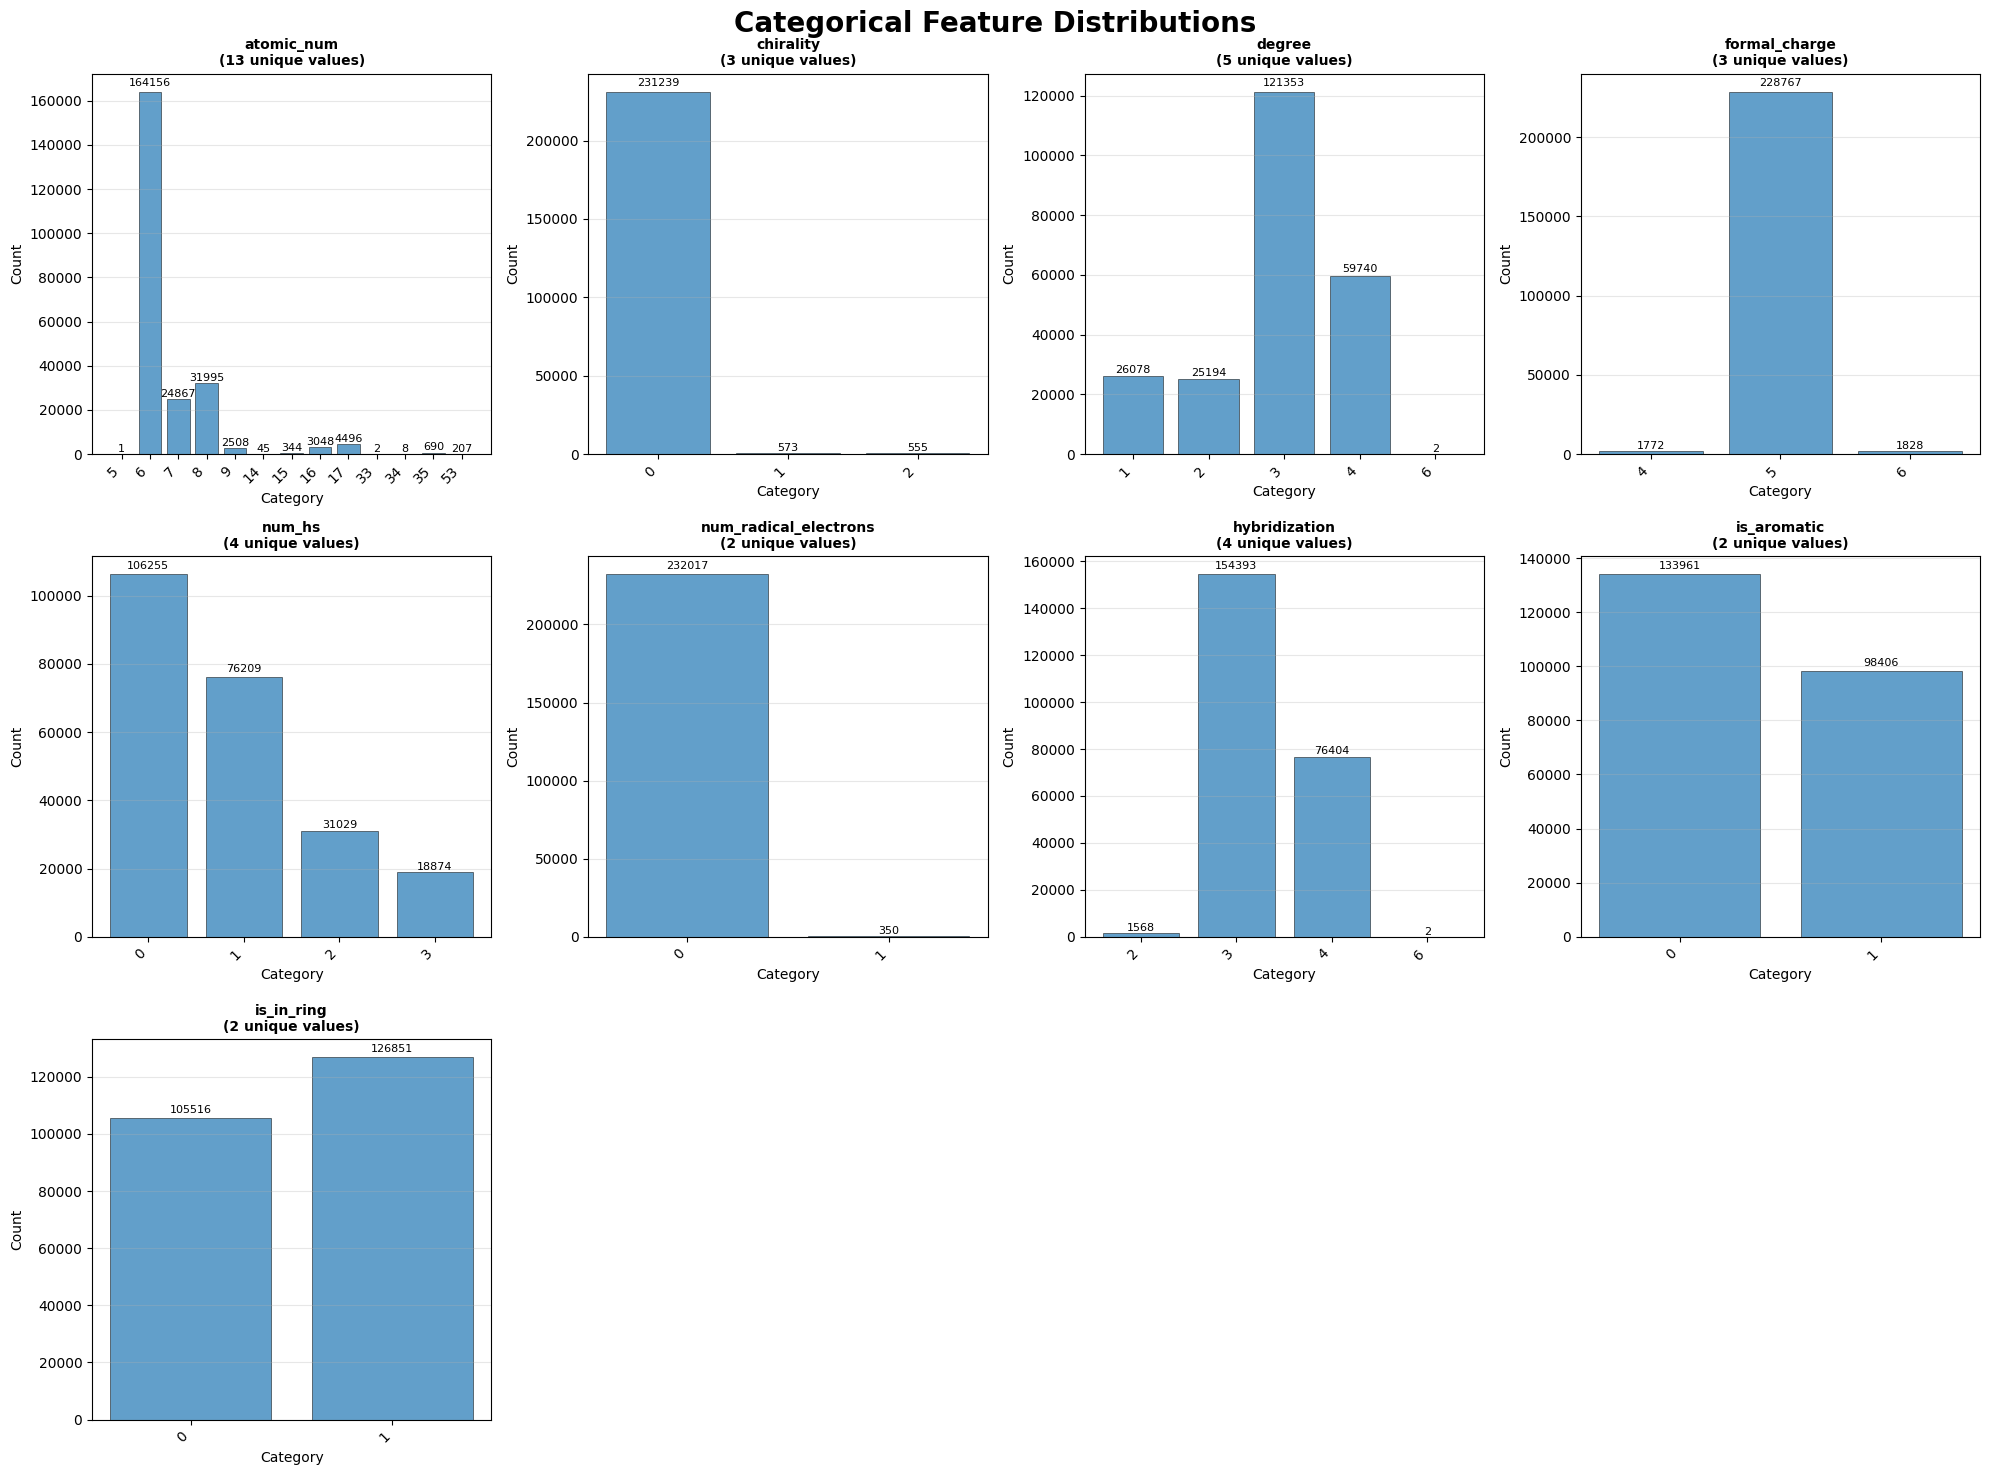

Category Summary Table (first 20 rows):
       Feature  Category   Count Percentage
0   atomic_num         6  164156     70.65%
1   atomic_num         8   31995     13.77%
2   atomic_num         7   24867     10.70%
3   atomic_num        17    4496      1.93%
4   atomic_num        16    3048      1.31%
5   atomic_num         9    2508      1.08%
6   atomic_num        35     690      0.30%
7   atomic_num        15     344      0.15%
8   atomic_num        53     207      0.09%
9   atomic_num        14      45      0.02%
10  atomic_num        34       8      0.00%
11  atomic_num        33       2      0.00%
12  atomic_num         5       1      0.00%
13   chirality         0  231239     99.51%
14   chirality         1     573      0.25%
15   chirality         2     555      0.24%
16      degree         3  121353     52.22%
17      degree         4   59740     25.71%
18      degree         1   26078     11.22%
19      degree         2   25194     10.84%


,Feature,Category,Count,Percentage
0,atomic_num,6,164156,70.65%
1,atomic_num,8,31995,13.77%
2,atomic_num,7,24867,10.70%
3,atomic_num,17,4496,1.93%
4,atomic_num,16,3048,1.31%
5,atomic_num,9,2508,1.08%
6,atomic_num,35,690,0.30%
7,atomic_num,15,344,0.15%
8,atomic_num,53,207,0.09%
9,atomic_num,14,45,0.02%


In [16]:
df_features = process_dataframe(clean_and_filtered_data)
full_categorical_analysis(df_features)

# Create Ground Truth Data (Benzene Ring)

In [ ]:
non_fused_benzene_extractor = BenzeneSubstructureExtractor()

# generate_gt_data(data_path='../../../data/cleaned_and_filtered/filtered_data.csv',
#                  output_path='../../../data/benzene_target',
#                  count_substructure_func=non_fused_benzene_extractor.get_substructure_count)

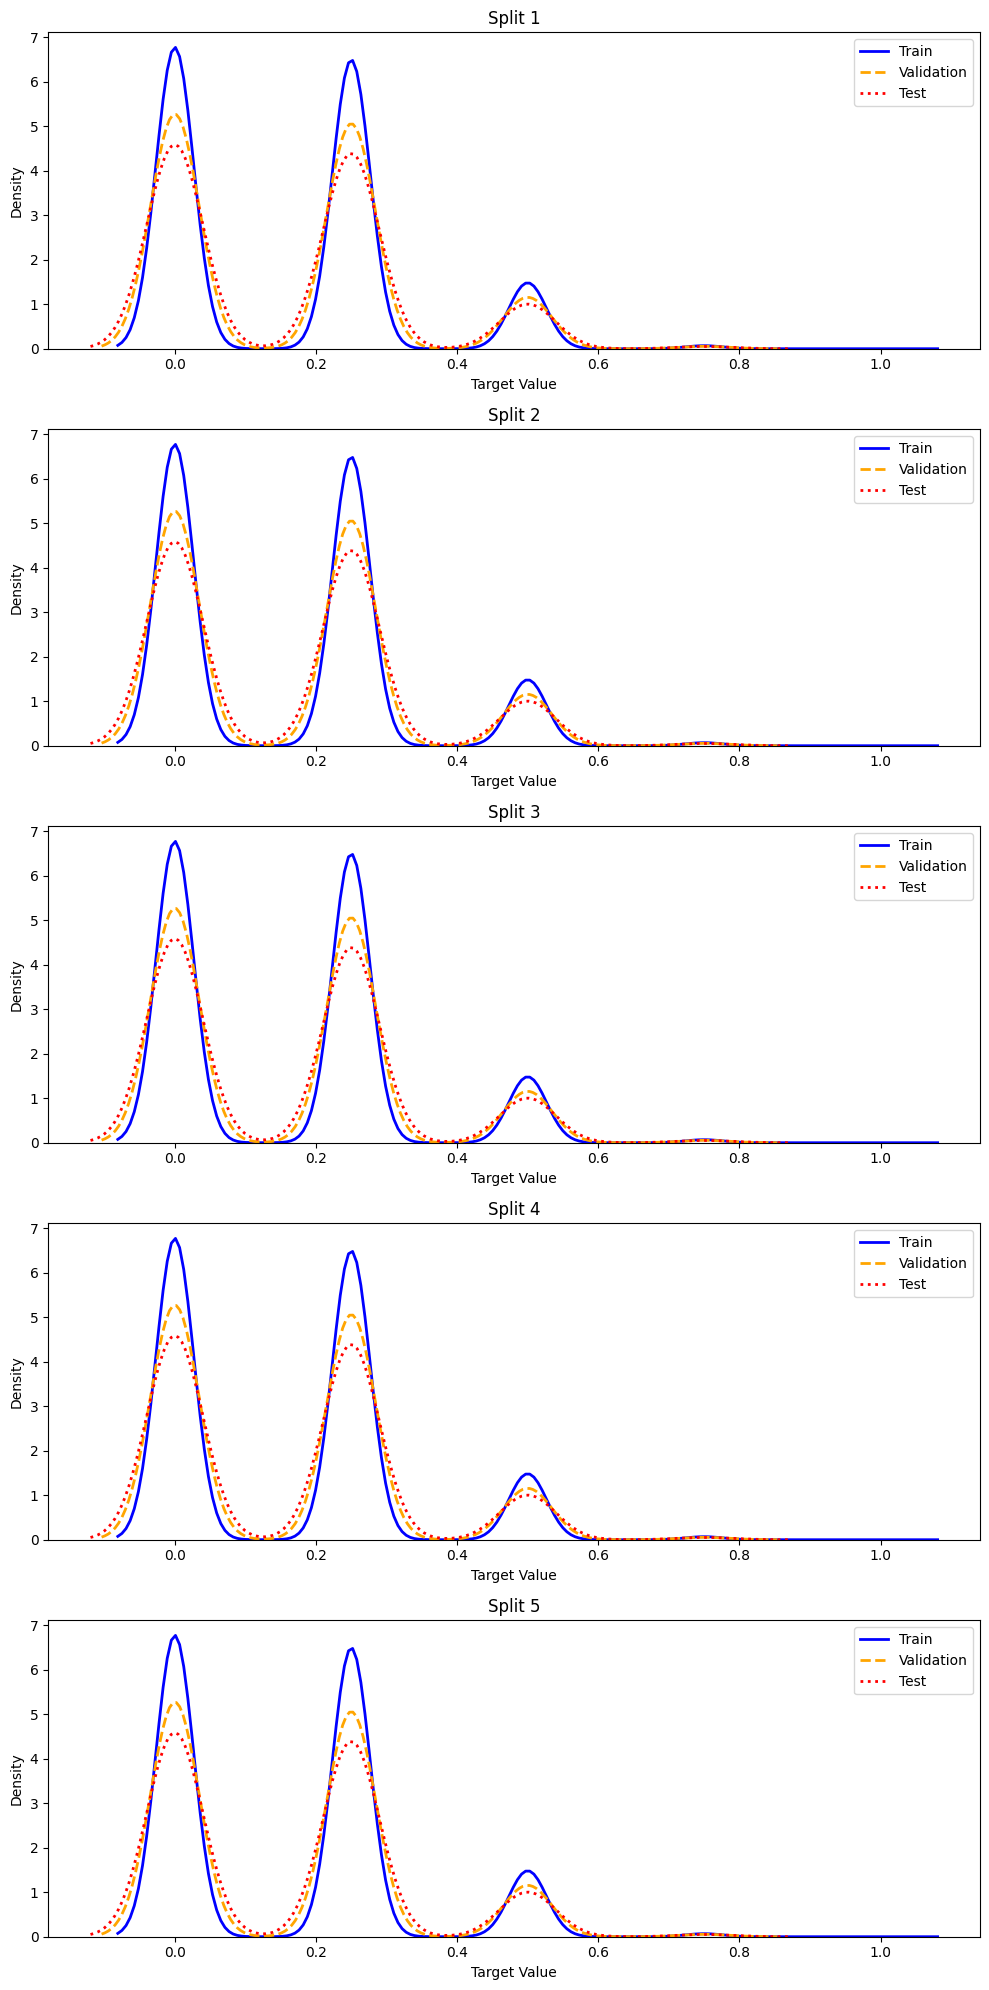

In [ ]:
import os
from glob import glob

base_output_path = '../../../data/benzene_target'

split_folders = sorted(glob(os.path.join(base_output_path, 'data_split_*')))

target_column_index = 1

num_splits = len(split_folders)

fig, axes = plt.subplots(nrows=num_splits, ncols=1, figsize=(10, 4 * num_splits))
for i, split_folder in enumerate(split_folders):
    train_path = os.path.join(split_folder, 'train.csv')
    val_path = os.path.join(split_folder, 'val.csv')
    test_path = os.path.join(split_folder, 'test.csv')

    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)

    train_values = train_df.iloc[:, target_column_index]
    val_values = val_df.iloc[:, target_column_index]
    test_values = test_df.iloc[:, target_column_index]

    ax = axes[i] if num_splits > 1 else axes
    sns.kdeplot(train_values, color='blue', linewidth=2, label='Train', ax=ax)
    sns.kdeplot(val_values, color='orange', linewidth=2, linestyle='dashed', label='Validation', ax=ax)
    sns.kdeplot(test_values, color='red', linewidth=2, linestyle='dotted', label='Test', ax=ax)

    ax.set_title(f'Split {i+1}')
    ax.set_xlabel('Target Value')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()

# Create Ground Truth Data (Largest Conjugated System)

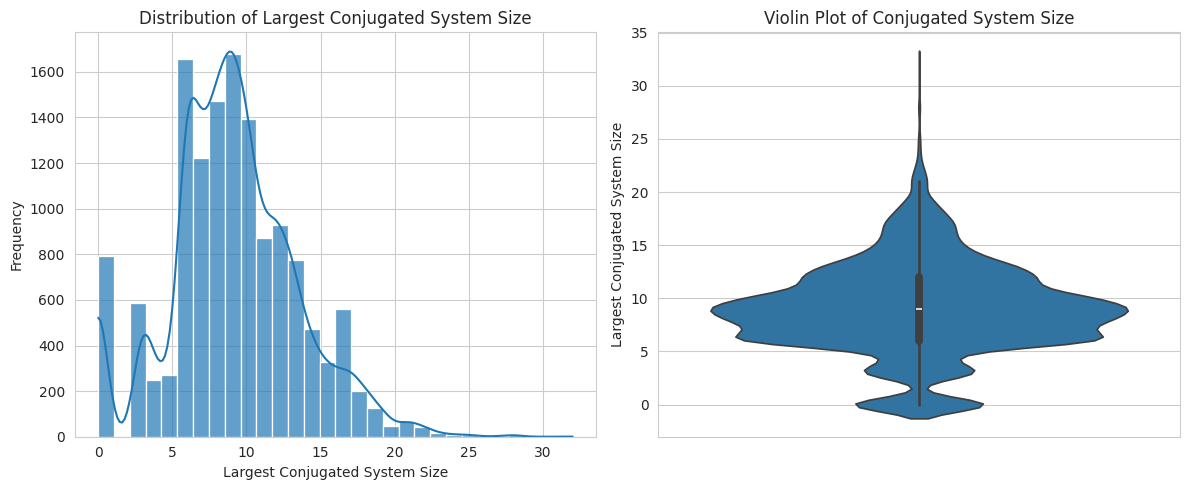

count    13792.000000
mean         9.099695
std          4.355229
min          0.000000
25%          6.000000
50%          9.000000
75%         12.000000
max         32.000000
dtype: float64


In [ ]:
largest_conjugated_system = LargestConjugatedSystemExtractor()

# Extract the largest conjugated system size for each molecule
conjugated_sizes = []
for idx, row in clean_and_filtered_data.iterrows():
    try:
        size = largest_conjugated_system.get_conjugated_system_size(row['SMILES'])
        conjugated_sizes.append(size)
    except Exception as e:
        print(f"Error processing row {idx}: {e}")
        conjugated_sizes.append(None)

# Create a clean series for plotting
conjugated_series = pd.Series([size for size in conjugated_sizes if size is not None])

# Set up the plotting style
plt.figure(figsize=(12, 5))
sns.set_style("whitegrid")

# Distribution plot with KDE
plt.subplot(1, 2, 1)
sns.histplot(conjugated_series, bins=30, kde=True, alpha=0.7)
plt.xlabel('Largest Conjugated System Size')
plt.ylabel('Frequency')
plt.title('Distribution of Largest Conjugated System Size')

# Violin plot for detailed distribution shape
plt.subplot(1, 2, 2)
sns.violinplot(y=conjugated_series)
plt.ylabel('Largest Conjugated System Size')
plt.title('Violin Plot of Conjugated System Size')

plt.tight_layout()
plt.show()

# Display summary statistics
print(conjugated_series.describe())

In [ ]:
largest_conjugated_system = LargestConjugatedSystemExtractor()
s
# generate_gt_data(data_path='../../../data/cleaned_and_filtered/filtered_data.csv',
#                  output_path='../../../data/largest_conjugated_system',
#                  count_substructure_func=largest_conjugated_system.get_conjugated_system_size)

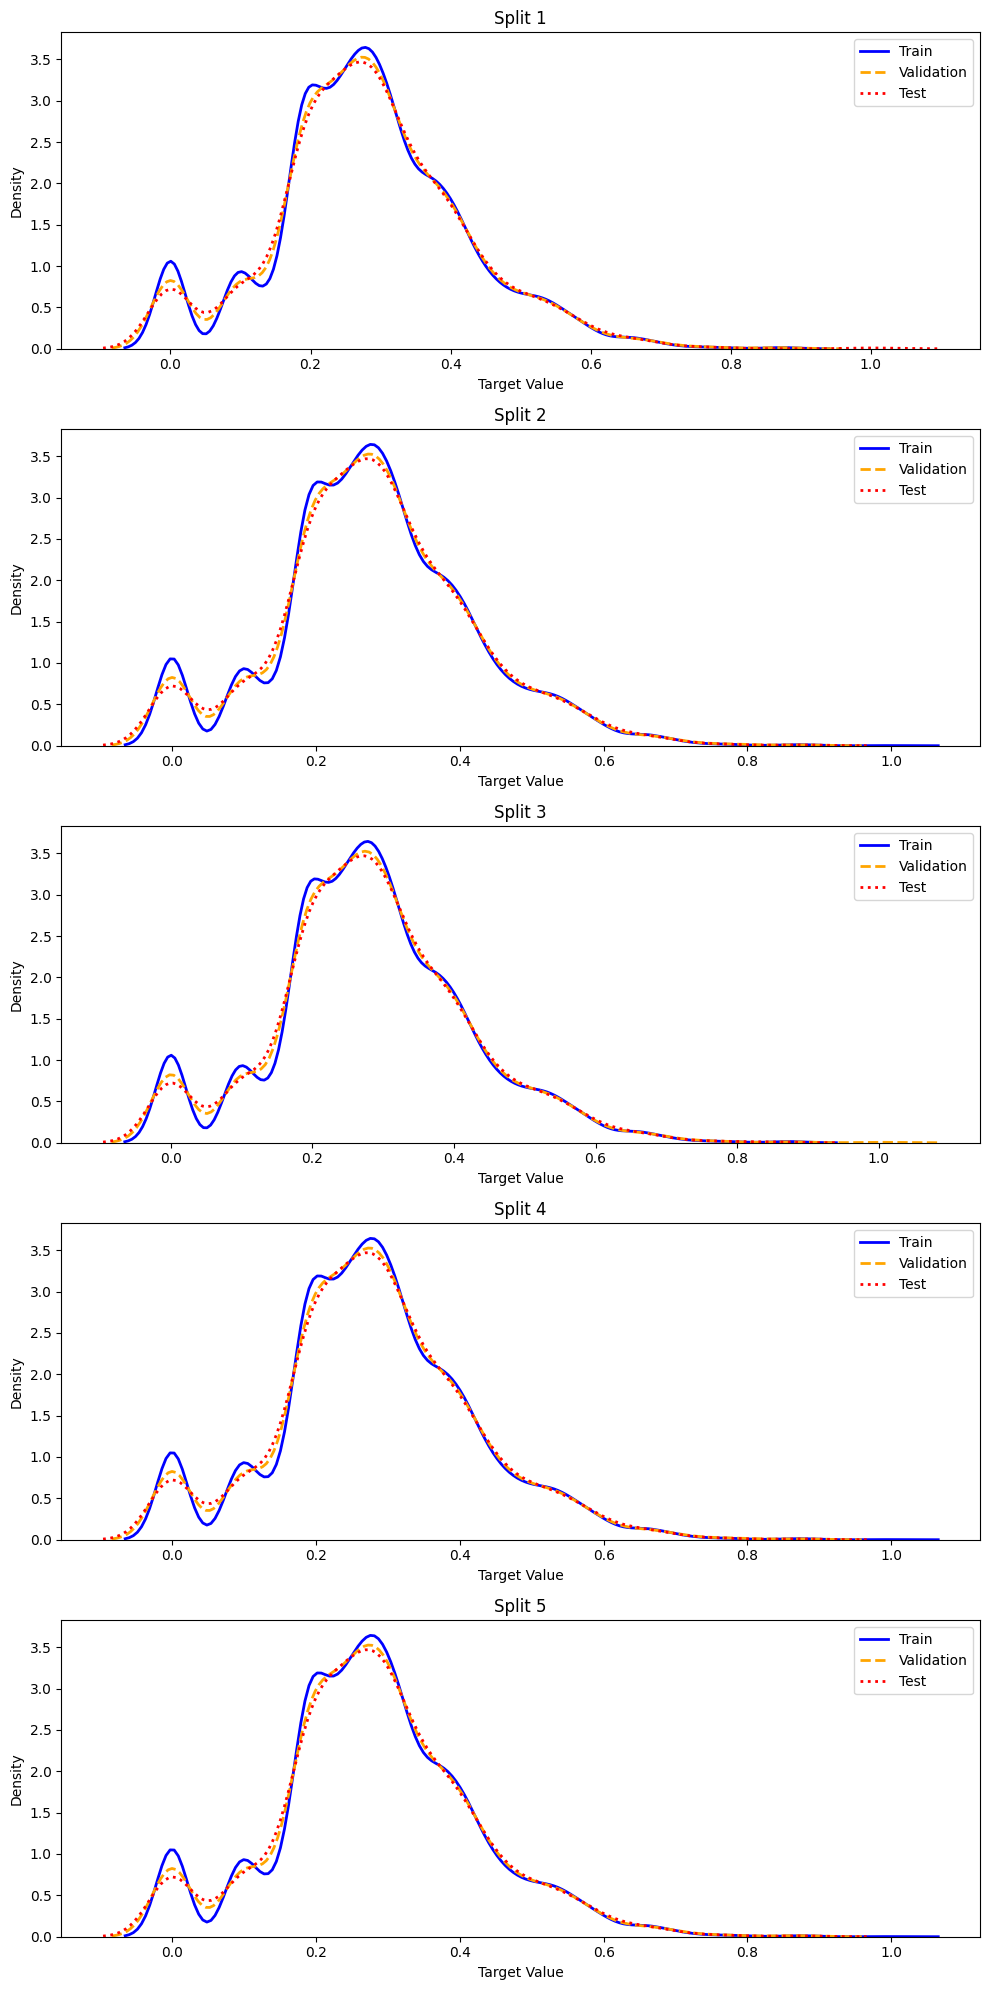

In [ ]:
base_output_path = '../../../data/largest_conjugated_system'

split_folders = sorted(glob(os.path.join(base_output_path, 'data_split_*')))

target_column_index = 1

num_splits = len(split_folders)

fig, axes = plt.subplots(nrows=num_splits, ncols=1, figsize=(10, 4 * num_splits))
for i, split_folder in enumerate(split_folders):
    train_path = os.path.join(split_folder, 'train.csv')
    val_path = os.path.join(split_folder, 'val.csv')
    test_path = os.path.join(split_folder, 'test.csv')

    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)

    train_values = train_df.iloc[:, target_column_index]
    val_values = val_df.iloc[:, target_column_index]
    test_values = test_df.iloc[:, target_column_index]

    ax = axes[i] if num_splits > 1 else axes
    sns.kdeplot(train_values, color='blue', linewidth=2, label='Train', ax=ax)
    sns.kdeplot(val_values, color='orange', linewidth=2, linestyle='dashed', label='Validation', ax=ax)
    sns.kdeplot(test_values, color='red', linewidth=2, linestyle='dotted', label='Test', ax=ax)

    ax.set_title(f'Split {i+1}')
    ax.set_xlabel('Target Value')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()

# Create Ground Truth Data (Hydrogen-Bond Donor)

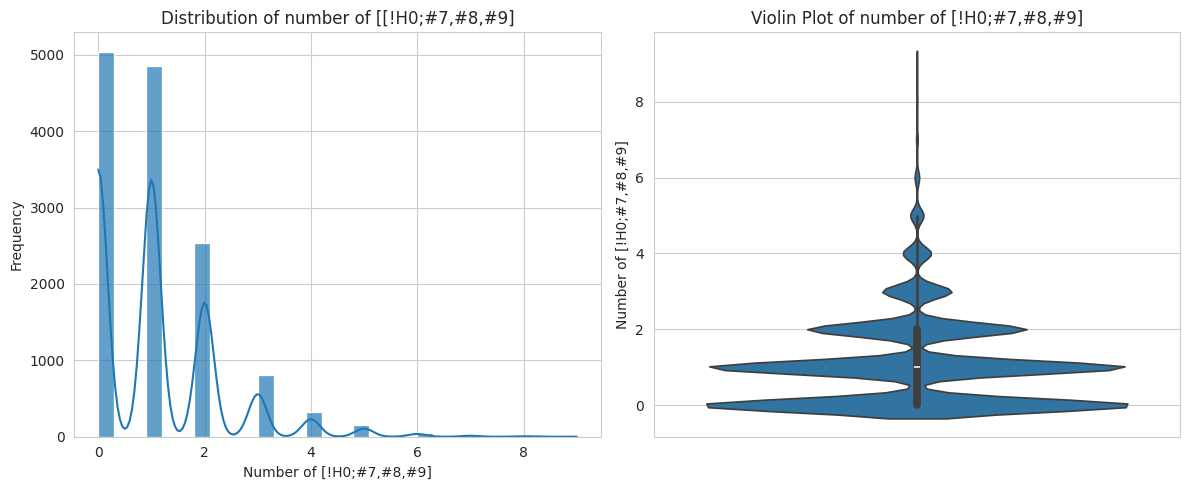

count    13792.000000
mean         1.083019
std          1.160836
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          9.000000
dtype: float64


In [ ]:
hbond_donor_extractor = HBondDonorExtractor()

conjugated_sizes = []
for idx, row in clean_and_filtered_data.iterrows():
    try:
        size = hbond_donor_extractor.get_hbond_donor_count(row['SMILES'])
        conjugated_sizes.append(size)
    except Exception as e:
        print(f"Error processing row {idx}: {e}")
        conjugated_sizes.append(None)

conjugated_series = pd.Series([size for size in conjugated_sizes if size is not None])

# Set up the plotting style
plt.figure(figsize=(12, 5))
sns.set_style("whitegrid")

# Distribution plot with KDE
plt.subplot(1, 2, 1)
sns.histplot(conjugated_series, bins=30, kde=True, alpha=0.7)
plt.xlabel('Number of [!H0;#7,#8,#9]')
plt.ylabel('Frequency')
plt.title('Distribution of number of [[!H0;#7,#8,#9]')

# Violin plot for detailed distribution shape
plt.subplot(1, 2, 2)
sns.violinplot(y=conjugated_series)
plt.ylabel('Number of [!H0;#7,#8,#9]')
plt.title('Violin Plot of number of [!H0;#7,#8,#9]')

plt.tight_layout()
plt.show()

# Display summary statistics
print(conjugated_series.describe())

In [ ]:
largest_conjugated_system = HBondDonorExtractor()

# generate_gt_data(data_path='../../../data/cleaned_and_filtered/filtered_data.csv',
#                  output_path='../../../data/hbond_donor',
#                  count_substructure_func=largest_conjugated_system.get_hbond_donor_count)

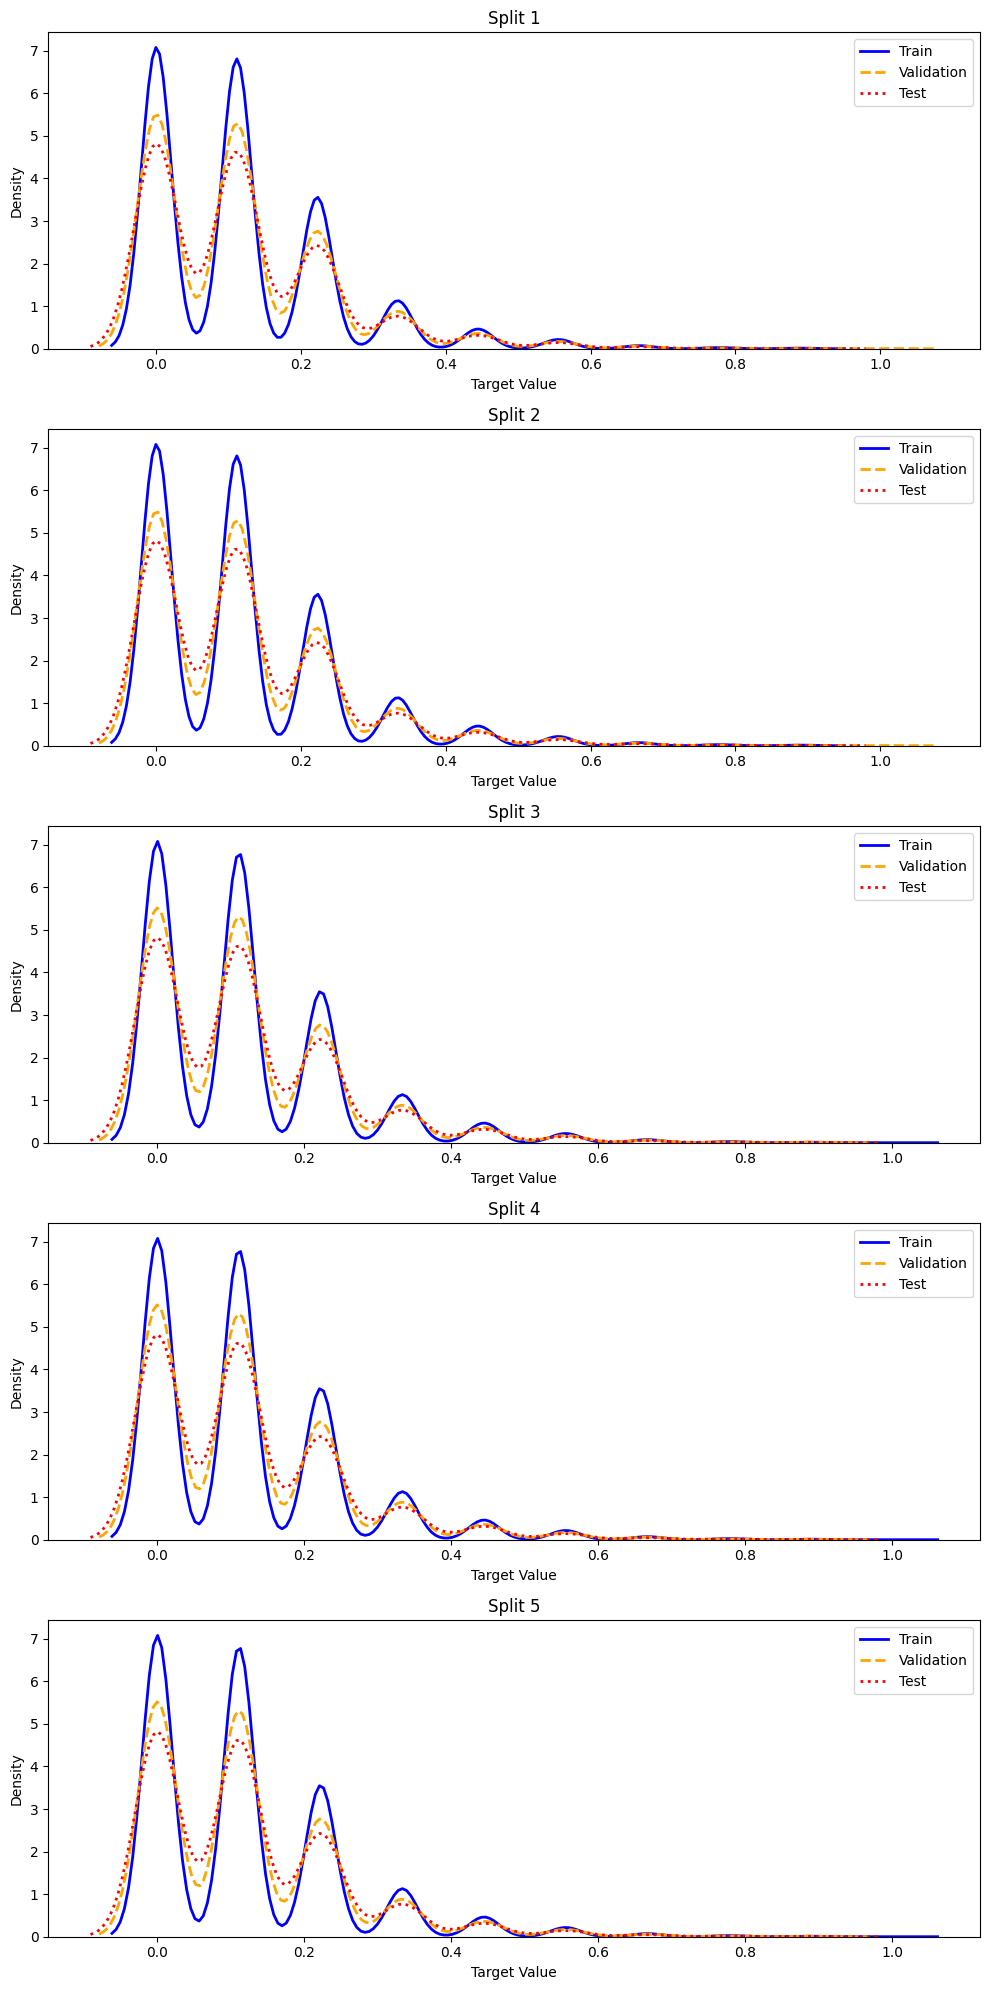

In [ ]:
base_output_path = '../../../data/hbond_donor'

split_folders = sorted(glob(os.path.join(base_output_path, 'data_split_*')))

target_column_index = 1

num_splits = len(split_folders)

fig, axes = plt.subplots(nrows=num_splits, ncols=1, figsize=(10, 4 * num_splits))
for i, split_folder in enumerate(split_folders):
    train_path = os.path.join(split_folder, 'train.csv')
    val_path = os.path.join(split_folder, 'val.csv')
    test_path = os.path.join(split_folder, 'test.csv')

    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)

    train_values = train_df.iloc[:, target_column_index]
    val_values = val_df.iloc[:, target_column_index]
    test_values = test_df.iloc[:, target_column_index]

    ax = axes[i] if num_splits > 1 else axes
    sns.kdeplot(train_values, color='blue', linewidth=2, label='Train', ax=ax)
    sns.kdeplot(val_values, color='orange', linewidth=2, linestyle='dashed', label='Validation', ax=ax)
    sns.kdeplot(test_values, color='red', linewidth=2, linestyle='dotted', label='Test', ax=ax)

    ax.set_title(f'Split {i+1}')
    ax.set_xlabel('Target Value')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()